In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Upload train.csv in Google Colab if not already in the working directory
if not os.path.exists("train.csv"):
    try:
        from google.colab import files
        print("Please upload train.csv from your computer:")
        uploaded = files.upload()
    except ImportError:
        raise FileNotFoundError("train.csv not found in the current directory.")

# Set plotting style and default figure size
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load dataset
df = pd.read_csv("train.csv")

print("Shape (rows, columns):", df.shape)
display(df.head())

print("\n--- DataFrame Info ---")
df.info()

missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100
missing_df = (
    pd.DataFrame({"missing_count": missing_count, "missing_pct": missing_pct.round(2)})
    .loc[lambda x: x["missing_count"] > 0]
    .sort_values(by="missing_count", ascending=False)
)

print(f"\nNumber of columns with missing values: {len(missing_df)}")
display(missing_df)

Please upload train.csv from your computer:


Saving train.csv to train.csv
Shape (rows, columns): (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null

,missing_count,missing_pct
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


In [2]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"],
}

for col, order in ordinal_map.items():
    if col in df.columns:
        df[col] = pd.Categorical(df[col], categories=order, ordered=True)

summary_rows = []
for col in df.columns:
    if isinstance(df[col].dtype, pd.CategoricalDtype):
        vtype = "ordinal" if df[col].cat.ordered else "categorical (nominal)"
    elif col == "OverallQual":
        vtype = "numeric (stored as int, conceptually ordinal)"
    elif pd.api.types.is_numeric_dtype(df[col]):
        vtype = "numerical"
    else:
        vtype = "categorical (nominal)"

    non_null_vals = df[col].dropna().unique()
    examples = ", ".join(map(str, non_null_vals[:3]))
    summary_rows.append(
        {
            "column_name": col,
            "type": vtype,
            "unique_values": df[col].nunique(dropna=True),
            "example_values": examples,
        }
    )

var_summary_df = pd.DataFrame(summary_rows)
display(var_summary_df)

,column_name,type,unique_values,example_values
0,Id,numerical,1460,"1, 2, 3"
1,MSSubClass,numerical,15,"60, 20, 70"
2,MSZoning,categorical (nominal),5,"RL, RM, C (all)"
3,LotFrontage,numerical,110,"65.0, 80.0, 68.0"
4,LotArea,numerical,1073,"8450, 9600, 11250"
...,...,...,...,...
76,MoSold,numerical,12,"2, 5, 9"
77,YrSold,numerical,5,"2008, 2007, 2006"
78,SaleType,categorical (nominal),9,"WD, New, COD"
79,SaleCondition,categorical (nominal),6,"Normal, Abnorml, Partial"


In [3]:
display(df[numeric_cols].describe().T)

target_num_cols = ["SalePrice", "GrLivArea", "LotArea"]
stats_records = []

for col in target_num_cols:
    s = df[col].dropna()
    q1, q3 = np.percentile(s, [25, 75])
    iqr = q3 - q1
    val_range = s.max() - s.min()
    mode_val = s.mode().iloc[0] if not s.mode().empty else np.nan
    skew_val = stats.skew(s, bias=False)
    kurt_val = stats.kurtosis(s, bias=False)

    if s.mean() > s.median():
        skew_note = "right skewed"
    elif s.mean() < s.median():
        skew_note = "left skewed"
    else:
        skew_note = "symmetric"

    stats_records.append(
        {
            "feature": col,
            "mean": round(s.mean(), 2),
            "median": round(s.median(), 2),
            "mode": mode_val,
            "std": round(s.std(), 2),
            "variance": round(s.var(), 2),
            "range": val_range,
            "IQR": round(iqr, 2),
            "skewness": round(skew_val, 4),
            "kurtosis": round(kurt_val, 4),
            "skew_note": skew_note,
        }
    )

stats_df = pd.DataFrame(stats_records)
display(stats_df)

for cat_col in ["Neighborhood", "HouseStyle"]:
    print(f"\n--- {cat_col} value_counts ---")
    display(df[cat_col].value_counts(dropna=False).to_frame("count"))
    print(f"Mode of {cat_col}: {df[cat_col].mode().iloc[0]}")

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


,feature,mean,median,mode,std,variance,range,IQR,skewness,kurtosis,skew_note
0,SalePrice,180921.20,163000.0,140000,79442.50,6.311111e+09,720100,84025.00,1.8829,6.5363,right skewed
1,GrLivArea,1515.46,1464.0,864,525.48,2.761296e+05,5308,647.25,1.3666,4.8951,right skewed
2,LotArea,10516.83,9478.5,7200,9981.26,9.962565e+07,213945,4048.00,12.2077,203.2433,right skewed



--- Neighborhood value_counts ---


,count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73


Mode of Neighborhood: NAmes

--- HouseStyle value_counts ---


,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


Mode of HouseStyle: 1Story


In [4]:
# 1. Check and remove duplicate rows
dup_count = df.duplicated().sum()
print("Duplicate rows found:", dup_count)
if dup_count > 0:
    df = df.drop_duplicates().copy()
    print("New shape after removing duplicates:", df.shape)

# 2. Check categorical columns for casing/whitespace/spelling inconsistencies
obj_cols = df.select_dtypes(include=["object"]).columns
for col in obj_cols:
    cleaned = df[col].dropna().astype(str).str.strip()
    lower_unique = set(cleaned.str.lower())
    raw_unique = set(cleaned)
    if len(raw_unique) != len(lower_unique):
        print(f"Casing/whitespace inconsistency in {col}: {sorted(raw_unique)}")
    df[col] = df[col].where(df[col].isna(), df[col].astype(str).str.strip())

# 3. Replace null with "None" where NA means feature absent
absent_feature_cols = ["PoolQC", "Alley", "Fence", "FireplaceQu", "GarageType"]
for col in absent_feature_cols:
    if col in df.columns:
        df[col] = df[col].fillna("None")

# 4. Impute remaining numeric columns (LotFrontage by Neighborhood median, fallback overall median)
for col in df.select_dtypes(include=[np.number]).columns:
    if df[col].isnull().sum() > 0:
        if col == "LotFrontage" and "Neighborhood" in df.columns:
            df[col] = df[col].fillna(df.groupby("Neighborhood")[col].transform("median"))
        df[col] = df[col].fillna(df[col].median())

# 5. Impute any remaining categorical/object columns
for col in df.select_dtypes(include=["object", "category"]).columns:
    if df[col].isnull().sum() > 0:
        if isinstance(df[col].dtype, pd.CategoricalDtype):
            if "None" not in df[col].cat.categories:
                df[col] = df[col].cat.add_categories(["None"])
            df[col] = df[col].fillna("None")
        else:
            df[col] = df[col].fillna("None")

print("Remaining missing values across dataset:", df.isnull().sum().sum())

# 6. Check impossible values
invalid_years = df[df["YearBuilt"] > df["YrSold"]]
print("Rows where YearBuilt > YrSold:", len(invalid_years))

area_cols = [c for c in df.columns if "Area" in c or "SF" in c]
neg_areas = sum((df[c] < 0).sum() for c in area_cols if pd.api.types.is_numeric_dtype(df[c]))
print("Negative values in area/SF columns:", neg_areas)

Duplicate rows found: 0
Remaining missing values across dataset: 0
Rows where YearBuilt > YrSold: 0
Negative values in area/SF columns: 0


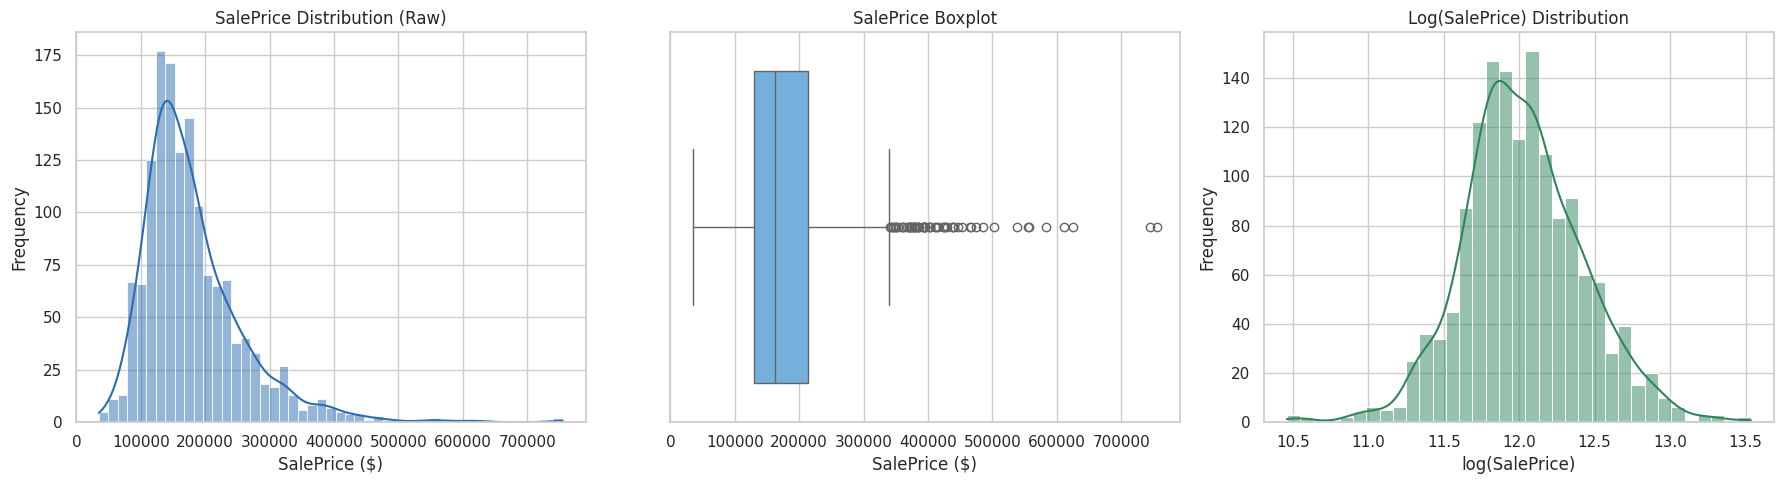

Skewness before log transform: 1.8809
Skewness after log transform:  0.1212


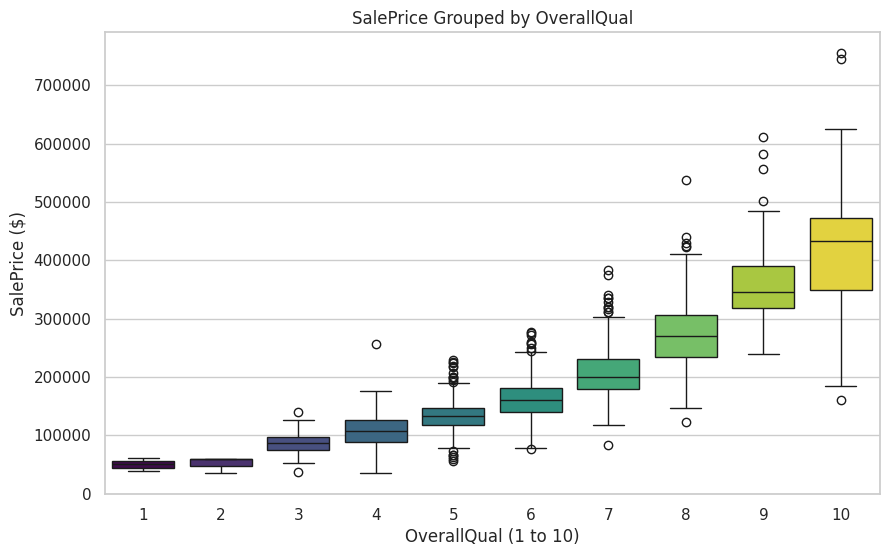

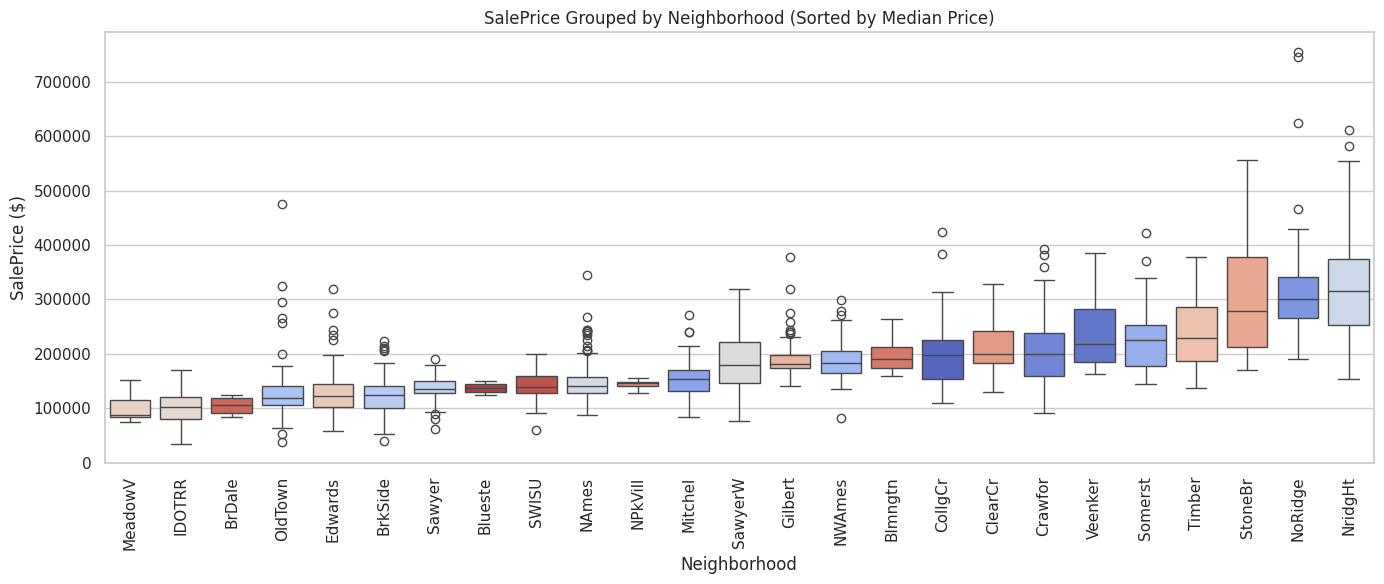

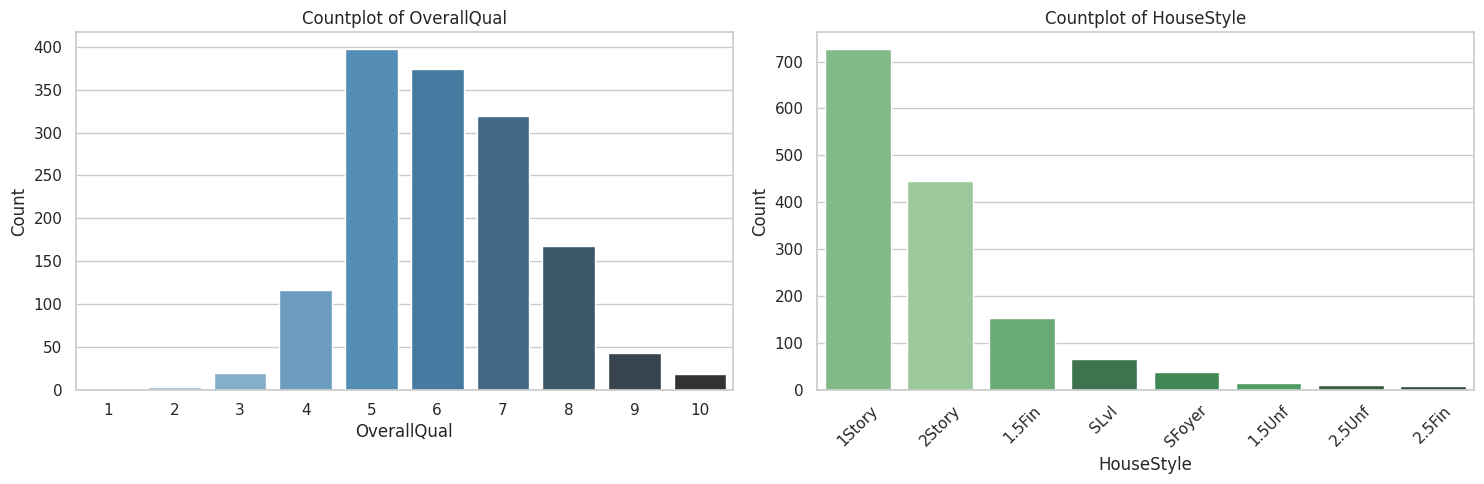

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Axis 1: Histogram of SalePrice with KDE overlay
sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="#2b6cb0")
axes[0].set_title("SalePrice Distribution (Raw)")
axes[0].set_xlabel("SalePrice ($)")
axes[0].set_ylabel("Frequency")

# Axis 2: Boxplot of SalePrice
sns.boxplot(x=df["SalePrice"], ax=axes[1], color="#63b3ed")
axes[1].set_title("SalePrice Boxplot")
axes[1].set_xlabel("SalePrice ($)")

# Axis 3: Histogram of log(SalePrice)
log_saleprice = np.log(df["SalePrice"])
sns.histplot(log_saleprice, kde=True, ax=axes[2], color="#2f855a")
axes[2].set_title("Log(SalePrice) Distribution")
axes[2].set_xlabel("log(SalePrice)")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"Skewness before log transform: {stats.skew(df['SalePrice']):.4f}")
print(f"Skewness after log transform:  {stats.skew(log_saleprice):.4f}")

# Boxplot of SalePrice grouped by OverallQual
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", hue="OverallQual", palette="viridis", legend=False)
plt.title("SalePrice Grouped by OverallQual")
plt.xlabel("OverallQual (1 to 10)")
plt.ylabel("SalePrice ($)")
plt.show()

# Boxplot of SalePrice grouped by Neighborhood (sorted by median price)
neigh_order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=neigh_order, hue="Neighborhood", palette="coolwarm", legend=False)
plt.title("SalePrice Grouped by Neighborhood (Sorted by Median Price)")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice ($)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Countplots of OverallQual and HouseStyle
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="OverallQual", ax=axes[0], hue="OverallQual", palette="Blues_d", legend=False)
axes[0].set_title("Countplot of OverallQual")
axes[0].set_xlabel("OverallQual")
axes[0].set_ylabel("Count")

sns.countplot(
    data=df,
    x="HouseStyle",
    order=df["HouseStyle"].value_counts().index,
    ax=axes[1],
    hue="HouseStyle",
    palette="Greens_d",
    legend=False,
)
axes[1].set_title("Countplot of HouseStyle")
axes[1].set_xlabel("HouseStyle")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [6]:
num_only = df.select_dtypes(include=[np.number])
cov_matrix = num_only.cov()
corr_matrix = num_only.corr(method="pearson")

top_corr = (
    corr_matrix["SalePrice"]
    .drop("SalePrice")
    .reindex(corr_matrix["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False).index)
    .head(10)
)

print("Top 10 numerical features correlated with SalePrice (Pearson):")
display(top_corr.to_frame("pearson_corr"))

print("Top 3 features — Covariance vs. Pearson Correlation with SalePrice:")
for col in top_corr.index[:3]:
    print(f"- {col}: Covariance = {cov_matrix.loc[col, 'SalePrice']:,.2f} | Correlation = {corr_matrix.loc[col, 'SalePrice']:.4f}")

# Optional: Spearman correlation for ordinal columns
ordinal_cols = ["OverallQual", "ExterQual", "KitchenQual", "GrLivArea", "GarageCars"]
ord_df = pd.DataFrame()
for col in ordinal_cols:
    if isinstance(df[col].dtype, pd.CategoricalDtype):
        ord_df[col] = df[col].cat.codes
    else:
        ord_df[col] = df[col]
ord_df["SalePrice"] = df["SalePrice"]

print("\nSpearman correlation with SalePrice (including ordinal features):")
display(ord_df.corr(method="spearman")["SalePrice"].sort_values(ascending=False).to_frame("spearman_corr"))

Top 10 numerical features correlated with SalePrice (Pearson):


,pearson_corr
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


Top 3 features — Covariance vs. Pearson Correlation with SalePrice:
- OverallQual: Covariance = 86,904.13 | Correlation = 0.7910
- GrLivArea: Covariance = 29,581,866.74 | Correlation = 0.7086
- GarageCars: Covariance = 38,020.18 | Correlation = 0.6404

Spearman correlation with SalePrice (including ordinal features):


,spearman_corr
SalePrice,1.000000
OverallQual,0.809829
GrLivArea,0.731310
GarageCars,0.690711
ExterQual,0.684014
KitchenQual,0.672849


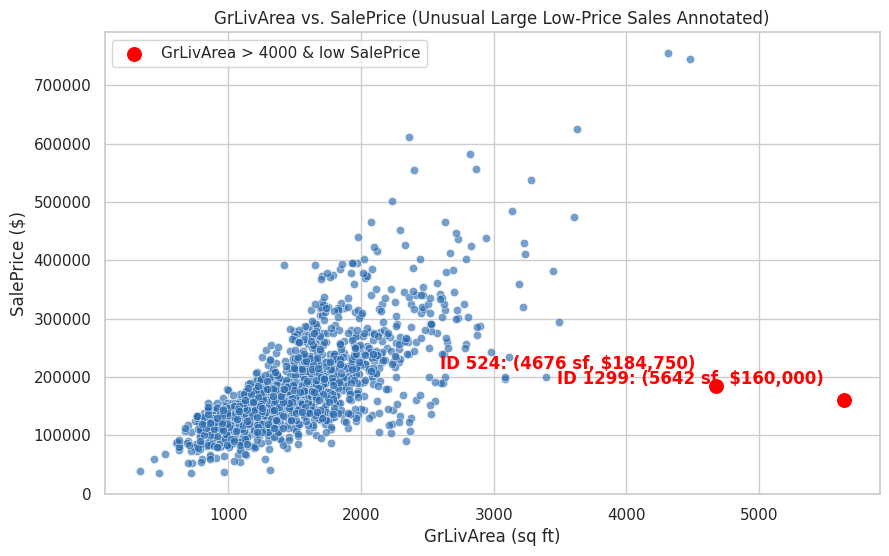

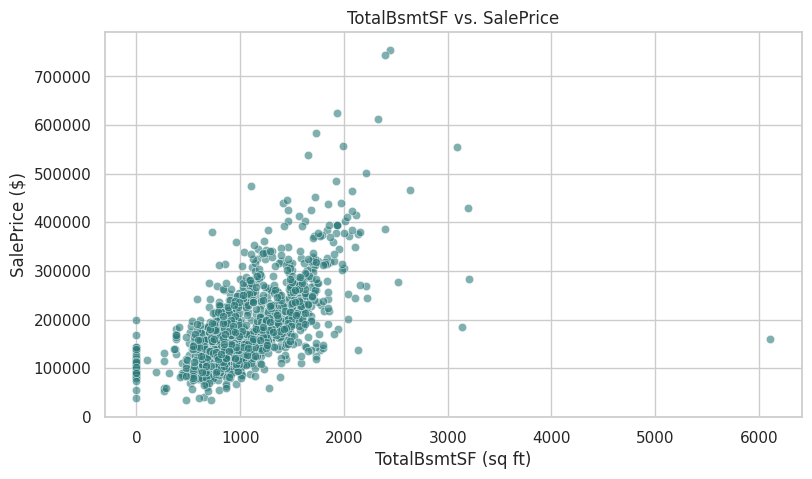

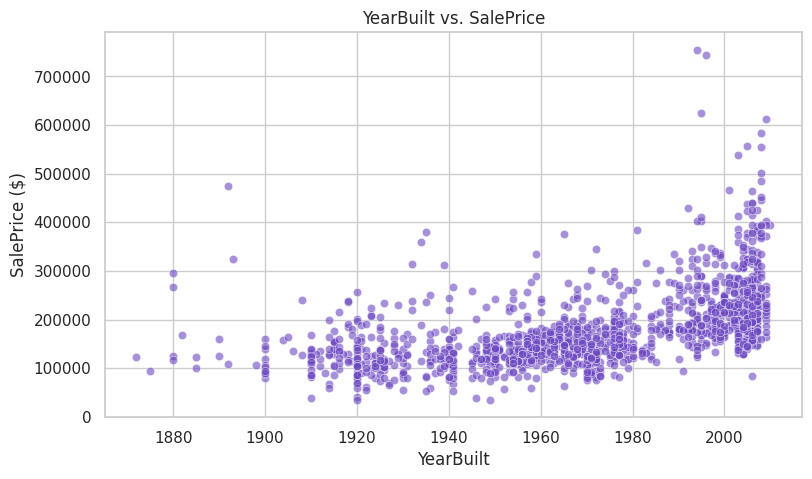

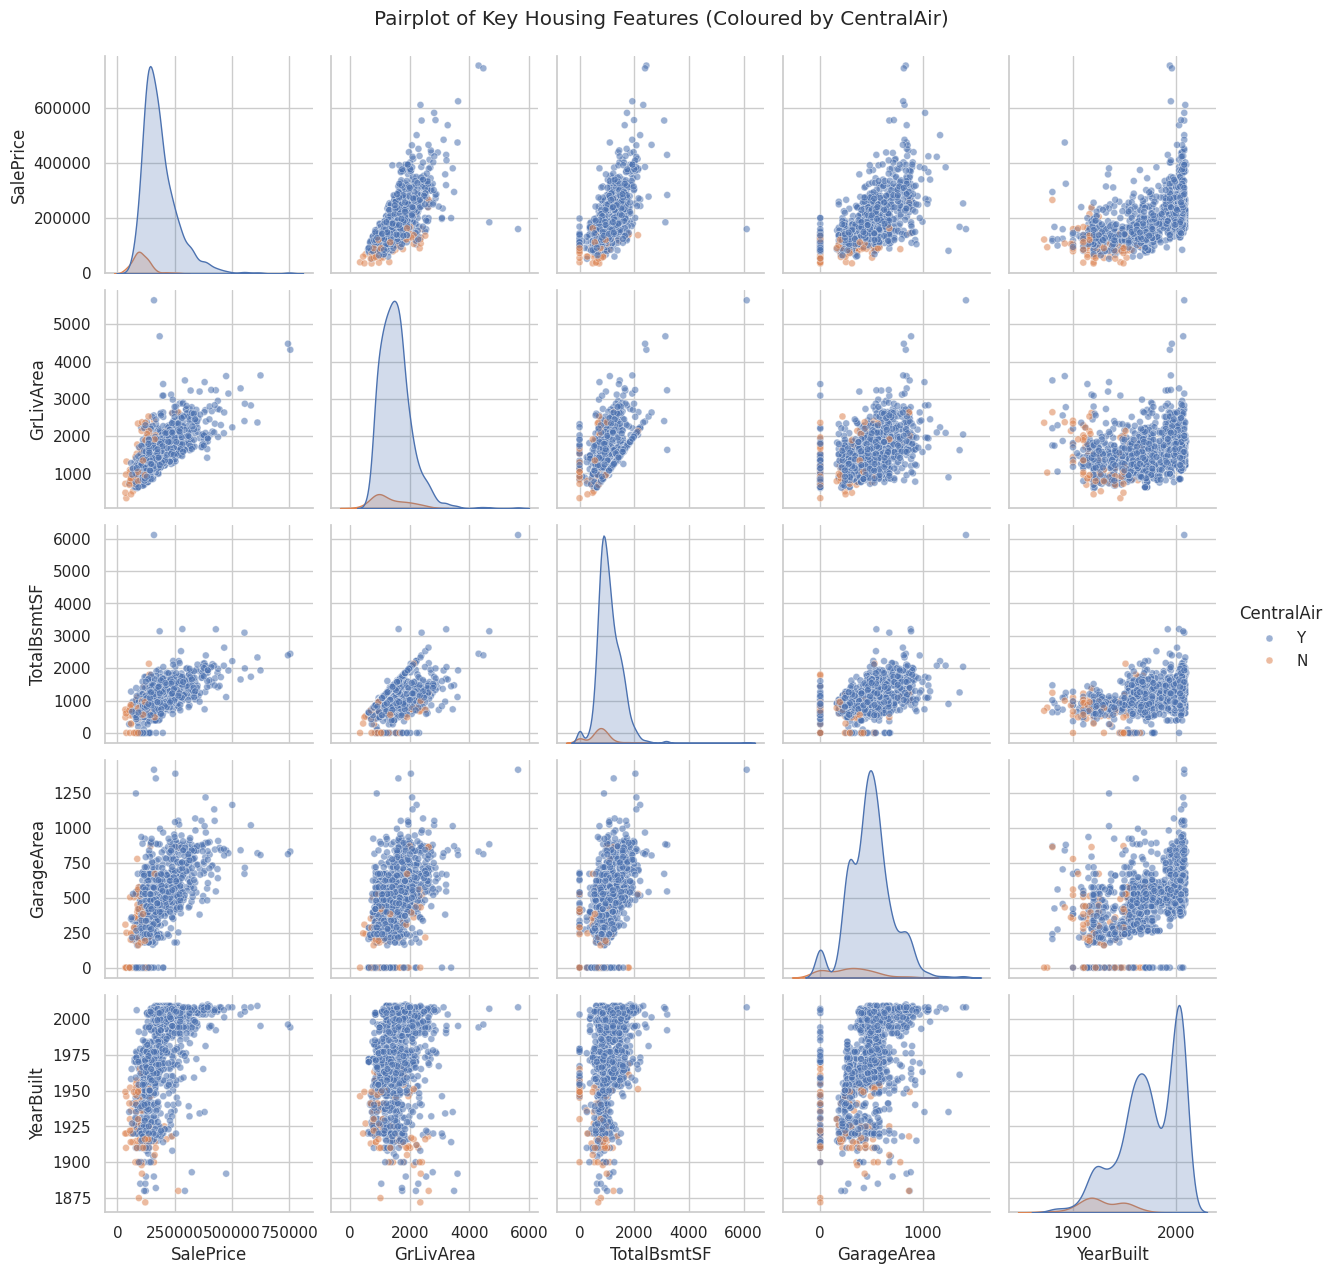

In [7]:
# 1. Scatter: GrLivArea vs SalePrice with annotation for large, low-price points
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.65, color="#2b6cb0")

unusual_pts = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
plt.scatter(
    unusual_pts["GrLivArea"],
    unusual_pts["SalePrice"],
    color="red",
    s=95,
    zorder=5,
    label="GrLivArea > 4000 & low SalePrice",
)
for idx, row in unusual_pts.iterrows():
    plt.annotate(
        f"ID {row['Id']}: ({int(row['GrLivArea'])} sf, ${int(row['SalePrice']):,})",
        (row["GrLivArea"], row["SalePrice"]),
        textcoords="offset points",
        xytext=(-15, 12),
        ha="right",
        color="red",
        fontweight="bold",
    )

plt.title("GrLivArea vs. SalePrice (Unusual Large Low-Price Sales Annotated)")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.show()

# 2. Scatter: TotalBsmtSF vs SalePrice
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice", alpha=0.6, color="#2c7a7b")
plt.title("TotalBsmtSF vs. SalePrice")
plt.xlabel("TotalBsmtSF (sq ft)")
plt.ylabel("SalePrice ($)")
plt.show()

# 3. Scatter: YearBuilt vs SalePrice
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df, x="YearBuilt", y="SalePrice", alpha=0.6, color="#6b46c1")
plt.title("YearBuilt vs. SalePrice")
plt.xlabel("YearBuilt")
plt.ylabel("SalePrice ($)")
plt.show()

# 4. Pairplot with KDE on diagonal coloured by CentralAir
selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
pair_grid = sns.pairplot(
    df[selected + ["CentralAir"]],
    hue="CentralAir",
    diag_kind="kde",
    plot_kws={"alpha": 0.55, "s": 25},
)
pair_grid.fig.suptitle("Pairplot of Key Housing Features (Coloured by CentralAir)", y=1.02)
plt.show()

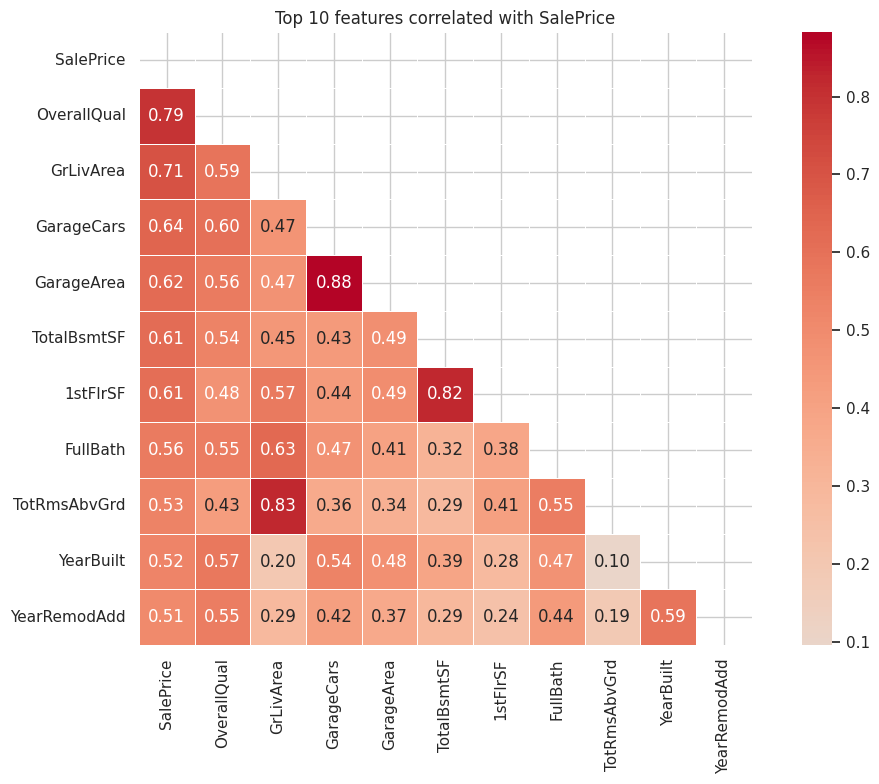

In [8]:
top10_features = ["SalePrice"] + top_corr.index.tolist()
corr_top = df[top10_features].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr_top,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
)
plt.title("Top 10 features correlated with SalePrice")
plt.tight_layout()
plt.show()

=== GrLivArea ===
IQR outliers count:     31
Z-score outliers count: 16
Overlap count:          16



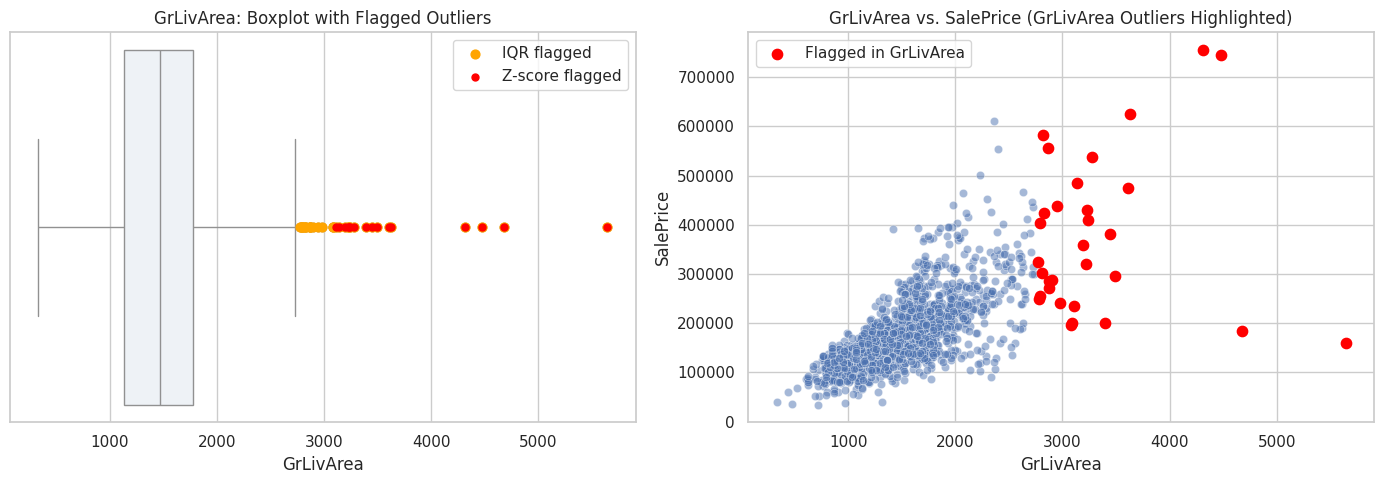

=== SalePrice ===
IQR outliers count:     61
Z-score outliers count: 22
Overlap count:          22



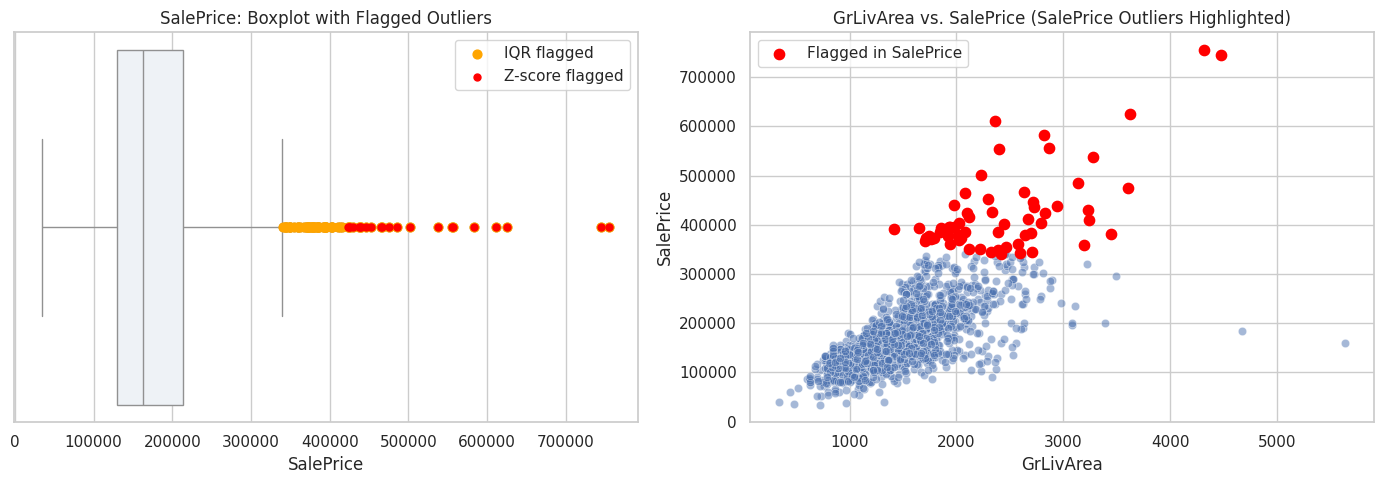

Original rows: 1460 | df_clean rows: 1458 | Removed rows: 2


In [9]:
def iqr_outliers(series):
    q1 = np.percentile(series.dropna(), 25)
    q3 = np.percentile(series.dropna(), 75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]


def zscore_outliers(series, threshold=3):
    s = series.dropna()
    z = (series - s.mean()) / s.std()
    return series[z.abs() > threshold]


for col in ["GrLivArea", "SalePrice"]:
    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col])
    overlap = a.index.intersection(b.index)

    print(f"=== {col} ===")
    print(f"IQR outliers count:     {len(a)}")
    print(f"Z-score outliers count: {len(b)}")
    print(f"Overlap count:          {len(overlap)}\n")

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Boxplot with outliers marked
    sns.boxplot(x=df[col], ax=axes[0], color="#edf2f7")
    axes[0].scatter(a.values, np.zeros(len(a)), color="orange", s=40, label="IQR flagged", zorder=4)
    axes[0].scatter(b.values, np.zeros(len(b)), color="red", s=25, label="Z-score flagged", zorder=5)
    axes[0].set_title(f"{col}: Boxplot with Flagged Outliers")
    axes[0].legend()

    # Scatter of GrLivArea vs SalePrice highlighting flagged points
    sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.5, ax=axes[1])
    flagged = df.loc[a.index.union(b.index)]
    axes[1].scatter(
        flagged["GrLivArea"],
        flagged["SalePrice"],
        color="red",
        s=55,
        label=f"Flagged in {col}",
        zorder=5,
    )
    axes[1].set_title(f"GrLivArea vs. SalePrice ({col} Outliers Highlighted)")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

# Decision: remove non-typical sales where GrLivArea > 4000 and SalePrice < 300000
non_typical_idx = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)].index
df_clean = df.drop(index=non_typical_idx).copy()
print(f"Original rows: {len(df)} | df_clean rows: {len(df_clean)} | Removed rows: {len(non_typical_idx)}")

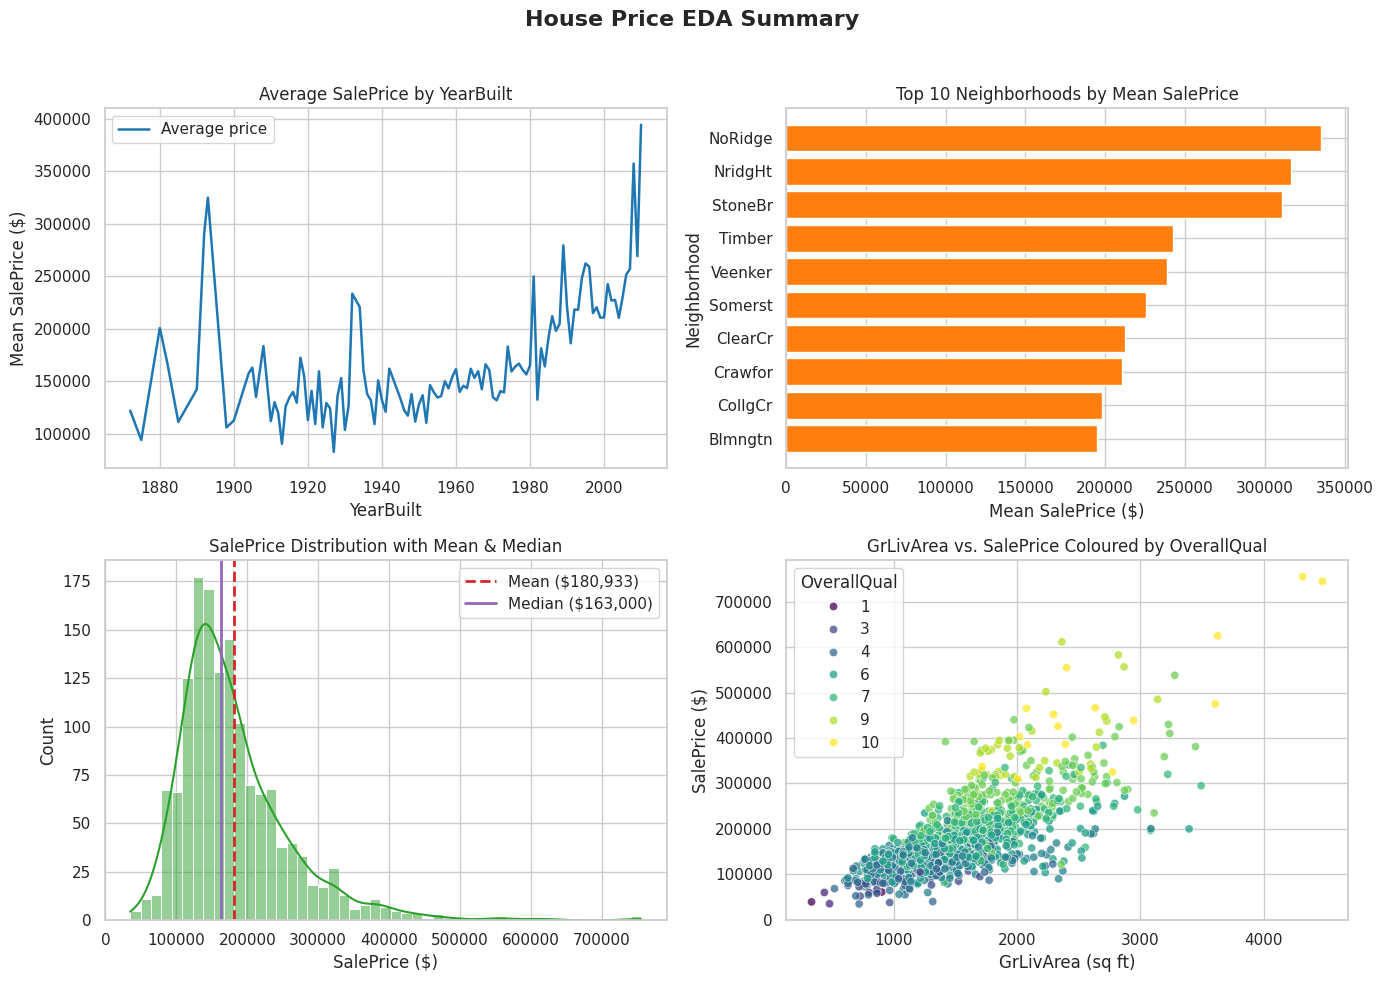

In [10]:
palette = sns.color_palette("tab10")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1 (Matplotlib line plot): Mean SalePrice by YearBuilt
yr_mean = df_clean.groupby("YearBuilt")["SalePrice"].mean().sort_index()
axes[0, 0].plot(yr_mean.index, yr_mean.values, color=palette[0], linewidth=1.8, label="Average price")
axes[0, 0].set_title("Average SalePrice by YearBuilt")
axes[0, 0].set_xlabel("YearBuilt")
axes[0, 0].set_ylabel("Mean SalePrice ($)")
axes[0, 0].legend()

# Panel 2 (Matplotlib horizontal bar plot): Top 10 Neighborhoods by mean SalePrice
top10_neigh = (
    df_clean.groupby("Neighborhood")["SalePrice"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)
axes[0, 1].barh(top10_neigh.index, top10_neigh.values, color=palette[1])
axes[0, 1].set_title("Top 10 Neighborhoods by Mean SalePrice")
axes[0, 1].set_xlabel("Mean SalePrice ($)")
axes[0, 1].set_ylabel("Neighborhood")

# Panel 3 (Seaborn histplot with KDE): SalePrice distribution with mean & median vertical lines
mean_val = df_clean["SalePrice"].mean()
median_val = df_clean["SalePrice"].median()
sns.histplot(df_clean["SalePrice"], kde=True, ax=axes[1, 0], color=palette[2])
axes[1, 0].axvline(mean_val, color=palette[3], linestyle="--", linewidth=2, label=f"Mean (${mean_val:,.0f})")
axes[1, 0].axvline(median_val, color=palette[4], linestyle="-", linewidth=2, label=f"Median (${median_val:,.0f})")
axes[1, 0].set_title("SalePrice Distribution with Mean & Median")
axes[1, 0].set_xlabel("SalePrice ($)")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend()

# Panel 4 (Seaborn scatter): GrLivArea vs SalePrice coloured by OverallQual
sns.scatterplot(
    data=df_clean,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    alpha=0.75,
    ax=axes[1, 1],
)
axes[1, 1].set_title("GrLivArea vs. SalePrice Coloured by OverallQual")
axes[1, 1].set_xlabel("GrLivArea (sq ft)")
axes[1, 1].set_ylabel("SalePrice ($)")

fig.suptitle("House Price EDA Summary", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("eda_dashboard.png", dpi=300)
plt.show()